In [1]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
pd.set_option('display.max_columns', None)
import yfinance as yf


In [2]:
from datetime import datetime, timedelta

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
papel = 'ITUB4.SA'
papeis_adicionais = ['BBAS3.SA', 'BBDC4.SA', 'SANB11.SA']

In [5]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [6]:
base = datetime.today().date() - timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=600, data_base=base)
#df_base = pp.buscar_dados_papeis_adicionais(df_base, papeis_adicionais)
df_base.tail(10)

[ITUB4.SA] Cache existente cobre de 2020-01-02 a 2025-08-18.
[ITUB4.SA] Cache cobre período solicitado (2023-03-02 a 2025-08-18).
[ITUB4.SA] Garantindo atualização dos últimos 5 dias do cache...
Index(['data', 'adj_close', 'close', 'Dividends', 'high', 'low', 'open',
       'Stock Splits', 'volume'],
      dtype='object', name='Price')
[ITUB4.SA] Últimos dias atualizados em memória com sucesso.
[ITUB4.SA] Retornando 615 linhas para o período solicitado.
⬇️ Baixando dados macro de 02/03/2022 a 19/08/2025...
Baixando série 432 (selic)...
Baixando série 433 (ipca)...
Baixando série 1 (dolar)...
💾 Dados salvos em cache: /palpiteiro/dados\macro_20220302_20250819.csv
[^BVSP] Cache existente cobre de 2020-01-02 a 2025-08-18.
[^BVSP] Cache cobre período solicitado (2023-03-02 a 2025-08-18).
[^BVSP] Garantindo atualização dos últimos 5 dias do cache...
Index(['data', 'adj_close', 'close', 'Dividends', 'high', 'low', 'open',
       'Stock Splits', 'volume'],
      dtype='object', name='Price')
[

,open,high,low,close,adj_close,volume,pct_change,vol,rsi,mm200_close,close_norm_mm200,macd,macd_signal,macd_hist,ADX_14,DMP_14,DMN_14,BBL_20_2.0,BBM_20_2.0,BBU_20_2.0,BBB_20_2.0,BBP_20_2.0,atr_5,atr_50,obv,vwap,cmf,tr,atr,atr_pct,tr_pct,mm5,mm20,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,adj_close_ibov,volume_ibov,adc_open_BBAS3,adc_high_BBAS3,adc_low_BBAS3,adc_close_BBAS3,adc_adj_close_BBAS3,adc_volume_BBAS3,adc_pct_change_BBAS3,adc_vol_BBAS3,adc_rsi_BBAS3,adc_mm200_close_BBAS3,adc_close_norm_mm200_BBAS3,adc_macd_BBAS3,adc_macd_signal_BBAS3,adc_macd_hist_BBAS3,adc_ADX_14_BBAS3,adc_DMP_14_BBAS3,adc_DMN_14_BBAS3,adc_BBL_20_2.0_BBAS3,adc_BBM_20_2.0_BBAS3,adc_BBU_20_2.0_BBAS3,adc_BBB_20_2.0_BBAS3,adc_BBP_20_2.0_BBAS3,adc_atr_5_BBAS3,adc_atr_50_BBAS3,adc_obv_BBAS3,adc_vwap_BBAS3,adc_cmf_BBAS3,adc_tr_BBAS3,adc_atr_BBAS3,adc_atr_pct_BBAS3,adc_tr_pct_BBAS3,adc_mm5_BBAS3,adc_mm20_BBAS3,adc_open_BBDC4,adc_high_BBDC4,adc_low_BBDC4,adc_close_BBDC4,adc_adj_close_BBDC4,adc_volume_BBDC4,adc_pct_change_BBDC4,adc_vol_BBDC4,adc_rsi_BBDC4,adc_mm200_close_BBDC4,adc_close_norm_mm200_BBDC4,adc_macd_BBDC4,adc_macd_signal_BBDC4,adc_macd_hist_BBDC4,adc_ADX_14_BBDC4,adc_DMP_14_BBDC4,adc_DMN_14_BBDC4,adc_BBL_20_2.0_BBDC4,adc_BBM_20_2.0_BBDC4,adc_BBU_20_2.0_BBDC4,adc_BBB_20_2.0_BBDC4,adc_BBP_20_2.0_BBDC4,adc_atr_5_BBDC4,adc_atr_50_BBDC4,adc_obv_BBDC4,adc_vwap_BBDC4,adc_cmf_BBDC4,adc_tr_BBDC4,adc_atr_BBDC4,adc_atr_pct_BBDC4,adc_tr_pct_BBDC4,adc_mm5_BBDC4,adc_mm20_BBDC4,adc_open_SANB11,adc_high_SANB11,adc_low_SANB11,adc_close_SANB11,adc_adj_close_SANB11,adc_volume_SANB11,adc_pct_change_SANB11,adc_vol_SANB11,adc_rsi_SANB11,adc_mm200_close_SANB11,adc_close_norm_mm200_SANB11,adc_macd_SANB11,adc_macd_signal_SANB11,adc_macd_hist_SANB11,adc_ADX_14_SANB11,adc_DMP_14_SANB11,adc_DMN_14_SANB11,adc_BBL_20_2.0_SANB11,adc_BBM_20_2.0_SANB11,adc_BBU_20_2.0_SANB11,adc_BBB_20_2.0_SANB11,adc_BBP_20_2.0_SANB11,adc_atr_5_SANB11,adc_atr_50_SANB11,adc_obv_SANB11,adc_vwap_SANB11,adc_cmf_SANB11,adc_tr_SANB11,adc_atr_SANB11,adc_atr_pct_SANB11,adc_tr_pct_SANB11,adc_mm5_SANB11,adc_mm20_SANB11
data,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-08-05,35.220001,35.930000,35.060001,35.689999,35.689999,48243500,0.011048,0.010961,51.516589,32.671368,1.092394,-0.287982,-0.369565,0.081582,15.501659,21.964996,18.213051,34.399524,35.195500,35.991476,4.523171,0.810624,0.761879,0.683290,8.947559e+08,35.560000,0.004261,0.869999,0.707300,0.019818,0.024377,35.230000,35.195500,15.0,0.26,5.5119,132971.0,134233.0,132682.0,133151.0,133151.0,2816372,18.780001,18.910000,18.580000,18.620001,18.620001,38162300,-0.005342,0.024587,25.772584,25.39620,0.733181,-0.818135,-0.722931,-0.095205,43.977975,8.436591,38.838960,18.481977,20.1355,21.789023,16.423956,0.041736,0.611542,0.544727,-206702500.0,18.703334,-0.285887,0.330000,0.539177,0.028957,0.017723,19.058,20.1355,15.61,15.880000,15.610000,15.690000,15.690000,31469200,0.001916,0.010084,45.307899,13.69680,1.145523,-0.156807,-0.146007,-0.010800,15.024964,16.004355,15.217655,15.265869,15.7950,16.324132,6.699987,0.400780,0.350990,0.349589,-4327100.0,15.726666,-0.187638,0.270000,0.336972,0.021477,0.017208,15.620,15.7950,26.400000,26.690001,26.090000,26.090000,26.090000,1739700,-0.009867,0.011618,36.515500,27.01115,0.965897,-0.702257,-0.709658,0.007402,27.550649,16.683085,25.208017,25.285570,26.8745,28.463430,11.824817,0.253136,0.663204,0.653644,36525000.0,26.290000,-0.039509,0.600000,0.643794,0.024676,0.022997,26.258,26.8745
2025-08-06,36.290001,37.150002,36.099998,36.139999,36.139999,39958600,0.012609,0.011105,55.778030,32.693659,1.105413,-0.195111,-0.334674,0.139563,16.669068,30.405347,15.717384,34.452170,35.184000,35.915830,4.160017,1.153157,0.901504,0.698824,9.347145e+08,36.463333,-0.048136,1.460003,0.761065,0.021059,0.040399,35.443999,35.184000,15.0,0.26,5.4802,133169.0,135241.0,133169.0,134538.0,134538.0,4891658,18.820000,18.959999,18.700001,18.

## Verificação da volatilidade recente

In [7]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-08-05,0.707300,0.019818,0.869999,0.024377
2025-08-06,0.761065,0.021059,1.460003,0.040399
2025-08-07,0.770989,0.020962,0.899998,0.024470
2025-08-08,0.744490,0.020105,0.400002,0.010802
2025-08-11,0.736312,0.019761,0.629997,0.016908
2025-08-12,0.755861,0.019875,1.010002,0.026558
2025-08-13,0.735442,0.019523,0.469997,0.012477
2025-08-14,0.734339,0.019520,0.720001,0.019139
2025-08-15,0.716172,0.019103,0.480003,0.012804


In [8]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 1.87%
Valorização sugerida: 2.80%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [9]:
valorizacao = 0.05
stop_loss = 0.03
DIAS_FUTURO = 5  # dias futuros para buscar a valorização

In [10]:
df = pp.calcular_target_com_stop(df_base, valorizacao_alvo_pct=valorizacao, dias_horizonte_alvo=DIAS_FUTURO, stop_loss_pct=stop_loss)
df['Target'].value_counts(normalize=True)

Target
0.0    0.888525
1.0    0.111475
Name: proportion, dtype: float64

In [26]:
# Preparar X e y para treino
DIAS_JANELA_X = 15  # janela de dados recentes que formam cada X
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True, tipo_drop_na='linhas')   

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:784: RuntimeWarning: Mean of empty slice
  linha['adc_close_norm_mean_geral_ultimo'] = np.nanmean(lista_close_norm_adicionais_ultimos)
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:784: RuntimeWarning: Mean of empty slice
  linha['adc_close_norm_mean_geral_ultimo'] = np.nanmean(lista_close_norm_adicionais_ultimos)
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:784: RuntimeWarning: Mean of empty slice
  linha['adc_close_norm_mean_geral_ultimo'] = np.nanmean(lista_close_norm_adicionais_ultimos)
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:784: Runtim

INFO: 199 linha(s) removidas de X e y devido a NaNs.


In [27]:
X_train.columns

Index(['close_norm_mean', 'close_norm_std', 'close_norm_max', 'close_norm_min',
       'close_norm_trend', 'retorno_mean', 'retorno_std', 'dias_alta_pct',
       'dias_queda_pct', 'retorno_medio_pos', 'retorno_medio_neg',
       'volume_mean', 'volume_std', 'volume_trend', 'volume_ult_vs_mean',
       'correl_retorno_volume', 'rsi_mean', 'rsi_std', 'rsi_ultimo',
       'rsi_trend', 'macd_mean', 'macd_std', 'macd_ultimo', 'macd_trend',
       'macd_signal_mean', 'macd_signal_std', 'macd_signal_ultimo',
       'macd_signal_trend', 'macd_hist_mean', 'macd_hist_std',
       'macd_hist_ultimo', 'macd_hist_trend', 'obv_mean', 'obv_std',
       'obv_ultimo', 'obv_trend', 'cmf_mean', 'cmf_std', 'cmf_ultimo',
       'cmf_trend', 'atr_pct_mean', 'atr_pct_std', 'atr_pct_ultimo',
       'atr_pct_trend', 'adx_ultimo', 'adx_trend', 'tendencia_forte_adx25',
       'bbands_largura_pct_ultimo', 'bbands_largura_pct_trend',
       'bbands_posicao_pct_ultimo', 'bbands_exaustao_compra',
       'bbands_exau

In [12]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_validacao_scaled = pd.DataFrame(scaler.transform(X_validacao), columns=X_validacao.columns, index=X_validacao.index)

In [13]:
X_train_scaled.columns

Index(['close_norm_mean', 'close_norm_std', 'close_norm_max', 'close_norm_min',
       'close_norm_trend', 'retorno_mean', 'retorno_std', 'dias_alta_pct',
       'dias_queda_pct', 'retorno_medio_pos', 'retorno_medio_neg',
       'volume_mean', 'volume_std', 'volume_trend', 'volume_ult_vs_mean',
       'correl_retorno_volume', 'rsi_mean', 'rsi_std', 'rsi_ultimo',
       'rsi_trend', 'macd_mean', 'macd_std', 'macd_ultimo', 'macd_trend',
       'macd_signal_mean', 'macd_signal_std', 'macd_signal_ultimo',
       'macd_signal_trend', 'macd_hist_mean', 'macd_hist_std',
       'macd_hist_ultimo', 'macd_hist_trend', 'obv_mean', 'obv_std',
       'obv_ultimo', 'obv_trend', 'cmf_mean', 'cmf_std', 'cmf_ultimo',
       'cmf_trend', 'atr_pct_mean', 'atr_pct_std', 'atr_pct_ultimo',
       'atr_pct_trend', 'adx_ultimo', 'adx_trend', 'tendencia_forte_adx25',
       'bbands_largura_pct_ultimo', 'bbands_largura_pct_trend',
       'bbands_posicao_pct_ultimo', 'bbands_exaustao_compra',
       'bbands_exau

In [14]:
# remover todas as colunas de papeis adicionais a principio
#X_train = X_train.loc[:, ~X_train.columns.str.contains('adc_')]
#X_validacao = X_validacao[X_train.columns]

In [15]:
X_train_scaled.tail()

,close_norm_mean,close_norm_std,close_norm_max,close_norm_min,close_norm_trend,retorno_mean,retorno_std,dias_alta_pct,dias_queda_pct,retorno_medio_pos,retorno_medio_neg,volume_mean,volume_std,volume_trend,volume_ult_vs_mean,correl_retorno_volume,rsi_mean,rsi_std,rsi_ultimo,rsi_trend,macd_mean,macd_std,macd_ultimo,macd_trend,macd_signal_mean,macd_signal_std,macd_signal_ultimo,macd_signal_trend,macd_hist_mean,macd_hist_std,macd_hist_ultimo,macd_hist_trend,obv_mean,obv_std,obv_ultimo,obv_trend,cmf_mean,cmf_std,cmf_ultimo,cmf_trend,atr_pct_mean,atr_pct_std,atr_pct_ultimo,atr_pct_trend,adx_ultimo,adx_trend,tendencia_forte_adx25,bbands_largura_pct_ultimo,bbands_largura_pct_trend,bbands_posicao_pct_ultimo,bbands_exaustao_compra,bbands_exaustao_venda,adc_close_norm_trend_BBAS3,adc_correl_com_principal_BBAS3,adc_adx_ultimo_BBAS3,adc_close_norm_trend_BBDC4,adc_correl_com_principal_BBDC4,adc_adx_ultimo_BBDC4,adc_close_norm_trend_SANB11,adc_correl_com_principal_SANB11,adc_adx_ultimo_SANB11,adc_close_norm_mean_geral_ultimo,selic_ultimo,selic_comparacao_anterior,selic_dias_desde_mudanca,ipca_ultimo,ipca_comparacao_anterior,ipca_dias_desde_mudanca,dolar_ultimo,dolar_trend,dolar_std,retorno_desde_mudanca_dolar,ibov_trend,ibov_std,retorno_desde_mudanca_ibov,ibov_amplitude,correl_papel_ibov,beta_papel_ibov,alpha_papel_vs_ibov_mean,close_norm_vs_adc_norm_mean_geral,retorno_acumulado_norm,dia_semana_0,dia_semana_1,dia_semana_2,dia_semana_3,dia_semana_4,feriado,proximo_dia_util
2025-03-26,-0.599106,2.381532,-0.498991,-0.863852,2.241325,1.744695,0.097994,2.430319,-2.288531,0.026324,-0.043399,0.639028,-0.698795,0.780090,0.298361,0.429430,0.816380,1.725248,1.032112,1.727845,0.404651,2.700113,1.441701,2.143981,0.109529,1.232794,1.046966,1.392136,1.102928,2.513254,1.367167,2.060249,0.713144,2.961666,1.596087,2.477133,-0.241393,-0.322630,-0.149426,0.841302,0.873134,-0.543555,0.428187,-0.782215,0.604037,0.953828,1.684488,2.393419,1.247813,0.756505,-0.256851,-0.21859,0.938655,-0.017725,-0.042674,1.846046,-0.130253,0.044697,1.707175,0.800963,0.114591,0.792530,2.871352,1.159099,-0.990255,-0.739393,-0.726198,2.896670,0.655363,-0.953690,-0.104820,-0.182815,2.547208,3.134476,0.168056,2.032634,0.658164,0.264919,0.206049,-1.479984,1.912937,-0.503052,-0.492864,2.028957,-0.508131,-0.503052,0.0,0.528362
2025-03-27,-0.525000,2.085549,-0.498991,-0.806888,2.015263,1.732047,0.102247,2.430319,-2.288531,0.009690,-0.043399,0.784274,-0.806428,0.513374,-0.060649,0.374575,0.949493,1.327320,1.062884,1.440651,0.543299,2.693890,1.424816,2.140070,0.194779,1.624687,1.139583,1.639907,1.307848,2.069976,1.058151,1.633279,0.904887,2.808628,1.868767,2.397349,-0.184081,-0.480489,0.060615,0.734459,0.786581,-0.385897,0.015927,-0.863892,0.642868,1.063807,1.684488,2.435045,1.399239,0.704929,-0.256851,-0.21859,0.981653,-0.005645,-0.018510,1.923044,-0.114752,0.228403,1.734562,0.781836,0.257425,0.777361,2.871352,1.159099,-0.958331,-0.739393,-0.726198,2.946914,0.703261,-0.926889,-0.105226,0.090395,2.418229,2.941407,0.535148,2.275963,0.797486,0.476801,0.239263,-1.442184,1.824598,-0.503052,-0.492864,-0.492864,1.967998,-0.503052,0.0,0.528362
2025-03-28,-0.468634,1.684643,-0.498991,-0.806888,1.642505,1.355815,0.385663,1.889269,-1.755870,0.168419,-0.307694,0.776357,-0.797219,0.103115,-0.621078,0.616683,1.025743,0.931967,0.491409,0.985631,0.673743,2.506456,1.305771,2.017313,0.289659,1.895859,1.188304,1.808228,1.447453,1.647285,0.567628,1.095961,1.064363,2.494485,1.655815,2.208872,-0.108179,-0.706639,0.245715,0.626180,0.719289,-0.425973,0.238927,-0.836361,0.497308,1.099674,-0.593652,2.361922,1.482289,0.400844,-0.256851,-0.21859,1.082552,0.038957,0.028198,1.915152,0.187315,0.306496,1.790848,1.130928,0.423110,0.615903,2.871352,1.159099,-0.926408,-0.739393,-0.726198,2.997159,0.753881,-0.803358,-0.108728,0.379128,2.229382,2.735318,-0.095737,2.275963,1.110874,0.801533,-0.605355,-1.589534,1.286011,-0.503052,-0.492864,-0.492864,-0.508131,1.987866,0.0,-1.892641
2025-03-31,-0.429210,1.330428,-0.498991,-0.8068

# Avaliar tamanho do conjunto de treino

In [16]:
modelo_template = LogisticRegression(solver='liblinear', penalty='l1', random_state=42, class_weight='balanced', C=0.001)
df_tamanhos = tr.avaliar_papel_em_diferentes_tamanhos_conjunto_treino(modelo_template, X_train_scaled, y_train, precisao_minima_desejada=0.4)


--- Avaliando Estratégia com Walk-Forward Rolante (Treino=120, Val=30, Passo=30) ---
    (Métrica: Recall na Precisão Mínima de 40%)
Fold 1: Treinando de 2024-01-10 a 2024-07-02 (120 amostras). Validando de 2024-07-03 a 2024-08-13 (30 amostras).
  Recall na Precisão >= 40%: 0.000
Fold 2: Treinando de 2024-02-23 a 2024-08-13 (120 amostras). Validando de 2024-08-14 a 2024-09-24 (30 amostras).
  AVISO: Nenhum evento positivo na janela de teste. Recall será 0.
Fold 3: Treinando de 2024-04-08 a 2024-09-24 (120 amostras). Validando de 2024-09-25 a 2024-11-05 (30 amostras).
  Recall na Precisão >= 40%: 0.000
Fold 4: Treinando de 2024-05-21 a 2024-11-05 (120 amostras). Validando de 2024-11-06 a 2024-12-19 (30 amostras).
  AVISO: Nenhum evento positivo na janela de teste. Recall será 0.
Fold 5: Treinando de 2024-07-03 a 2024-12-19 (120 amostras). Validando de 2024-12-20 a 2025-02-05 (30 amostras).
  Recall na Precisão >= 40%: 0.000
Fold 6: Treinando de 2024-08-14 a 2025-02-05 (120 amostras). V

In [17]:
df_tamanhos

,recall_medio_na_prec_min,recall_std_na_prec_min,prob_sucesso_folds,tamanho_janela_treino
0,0.0,0.0,0.0,120
1,0.0,0.0,0.0,180
2,0.0,0.0,0.0,250
3,0.0,0.0,0.0,375
4,0.0,0.0,0.0,500


# Prosseguimos com o tamanho de X definido

In [18]:
#tamanho_X = 250
#X_train = X_train.iloc[-tamanho_X:]
#y_train = y_train.iloc[-tamanho_X:]
#QX_train.shape, y_train.shape

# LogisticRegression

# otimização de parametris

In [19]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import make_scorer, average_precision_score, f1_score # PR AUC é bom para desbalanceados

def otimizar_hiperparametros_logreg(X_super_treino, y_super_treino, n_splits_cv=5,precisao_minima_para_otimizacao=0.50):
    """
    Encontra os melhores hiperparâmetros para a Regressão Logística usando
    GridSearchCV com TimeSeriesSplit.

    Args:
        X_super_treino: Seu DataFrame de "super treino" (ex: os 510 dias).
        y_super_treino: Seus alvos correspondentes.
        n_splits_cv (int): Número de folds para a validação cruzada temporal.

    Returns:
        O melhor modelo treinado encontrado pelo GridSearchCV.
    """
    print(f"\n--- Iniciando Otimização de Hiperparâmetros com TimeSeriesSplit (n_splits={n_splits_cv}) ---")
    
    # 1. Definir o splitter de validação cruzada para séries temporais
    tscv = TimeSeriesSplit(n_splits=n_splits_cv)

    # 2. Definir o modelo base (não treinado)
    # Aumentar max_iter para garantir que solvers como 'saga' e 'lbfgs' convirjam.
    class_weight = 'balanced'
    log_reg_template = LogisticRegression(random_state=42, max_iter=5000, class_weight=class_weight)

    # 3. Definir o "grid" de parâmetros a serem testados
    param_grid = [
        {
            'penalty': ['l1'], # Penalidade Lasso (seleção de features)
            'solver': ['liblinear', 'saga'],
            'C': np.logspace(-4, 1, 6) # Isso testa: [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]                                        
        },
        {
            'penalty': ['l2'], # Penalidade Ridge (encolhimento de features)
            'solver': ['liblinear', 'lbfgs', 'saga'],
            'C': np.logspace(-4, 1, 6) # Isso testa: [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]                                        
        }
    ]

    # 4. Definir a métrica de scoring
    # 'roc_auc' é bom, mas 'average_precision' (PR AUC) é muitas vezes melhor para
    # dados desbalanceados e quando a precisão na classe positiva é importante.
    #scorer = make_scorer(average_precision_score)
    scorer = make_scorer(f1_score)

    #custom_scorer = make_scorer(
    #    recall_at_min_precision_scorer,
    ###    needs_proba=True,
    #    greater_is_better=True, # Queremos maximizar este score
    #    min_precision=precisao_minima_para_otimizacao # Passa o parâmetro para a nossa função
    #)

    # 5. Configurar e executar o GridSearchCV
    grid_search = GridSearchCV(
        estimator=log_reg_template,
        param_grid=param_grid,
        scoring=scorer,
        cv=tscv, # Usar o splitter temporal
        n_jobs=-1, # Usar todos os cores da CPU
        verbose=1  # Mostrar progresso
    )

    grid_search.fit(X_super_treino, y_super_treino)

    print("\n--- Resultados da Otimização ---")
    print(f"Melhor Score ({scorer}): {grid_search.best_score_:.4f}")
    print("Melhores Parâmetros Encontrados:")
    print(grid_search.best_params_)

    # O grid_search.best_estimator_ já é o modelo treinado com os melhores parâmetros
    # em todo o X_super_treino.
    return grid_search.best_estimator_

In [23]:
modelo_otimizado = otimizar_hiperparametros_logreg(X_train_scaled, y_train, n_splits_cv=5, precisao_minima_para_otimizacao=0.4)
modelo_otimizado


--- Iniciando Otimização de Hiperparâmetros com TimeSeriesSplit (n_splits=5) ---
Fitting 5 folds for each of 30 candidates, totalling 150 fits

--- Resultados da Otimização ---
Melhor Score (make_scorer(f1_score, response_method='predict')): 0.1841
Melhores Parâmetros Encontrados:
{'C': np.float64(0.0001), 'penalty': 'l2', 'solver': 'liblinear'}


LogisticRegression(C=np.float64(0.0001), class_weight='balanced', max_iter=5000,
                   random_state=42, solver='liblinear')

AUC no treino: 0.693
AUC na validação: 0.624
Diferença AUC (Treino - Validação): 0.070
PR AUC no treino: 0.353
PR AUC na validação: 0.397
Diferença PR AUC (Treino - Validação): -0.044
F1 Score no treino: 0.345
F1 Score na validação: 0.064


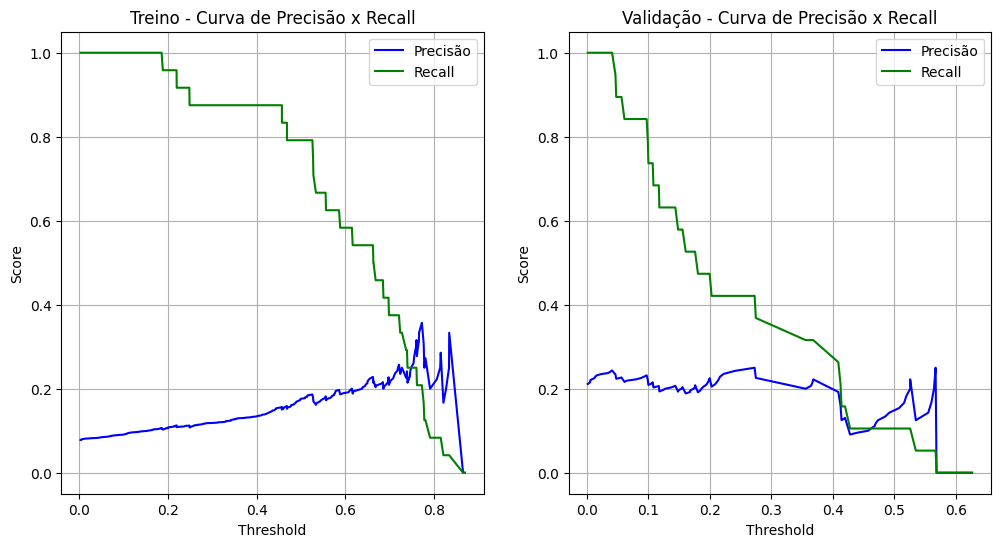

(np.float64(0.693390396879588),
 np.float64(0.6238190018221492),
 np.float64(0.06957139505743881),
 np.float64(0.35317048548220115),
 np.float64(0.397397486612818),
 np.float64(0.34464929680774586),
 np.float64(0.06399505256648114))

In [24]:
class_weight = 'balanced' #{0:1, 1:3}  # Ajustar pesos para lidar com desbalanceamento
modelo_rl = LogisticRegression(solver='liblinear', penalty='l1', max_iter=5000,random_state=42, class_weight=class_weight, C=0.0001)
modelo_rl.fit(X_train, y_train)
tr.comparar_auc_conjuntos(modelo_rl, X_train, y_train, X_validacao, y_validacao)

In [25]:
X_train.columns

Index(['close_norm_mean', 'close_norm_std', 'close_norm_max', 'close_norm_min',
       'close_norm_trend', 'retorno_mean', 'retorno_std', 'dias_alta_pct',
       'dias_queda_pct', 'retorno_medio_pos', 'retorno_medio_neg',
       'volume_mean', 'volume_std', 'volume_trend', 'volume_ult_vs_mean',
       'correl_retorno_volume', 'rsi_mean', 'rsi_std', 'rsi_ultimo',
       'rsi_trend', 'macd_mean', 'macd_std', 'macd_ultimo', 'macd_trend',
       'macd_signal_mean', 'macd_signal_std', 'macd_signal_ultimo',
       'macd_signal_trend', 'macd_hist_mean', 'macd_hist_std',
       'macd_hist_ultimo', 'macd_hist_trend', 'obv_mean', 'obv_std',
       'obv_ultimo', 'obv_trend', 'cmf_mean', 'cmf_std', 'cmf_ultimo',
       'cmf_trend', 'atr_pct_mean', 'atr_pct_std', 'atr_pct_ultimo',
       'atr_pct_trend', 'adx_ultimo', 'adx_trend', 'tendencia_forte_adx25',
       'bbands_largura_pct_ultimo', 'bbands_largura_pct_trend',
       'bbands_posicao_pct_ultimo', 'bbands_exaustao_compra',
       'bbands_exau

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: 42d3b9e7092646af9cd1d08945add394 para ITUB4.SA_15dias_x_0.05val_5dias_alvo
AUC no treino: 0.779
AUC na validação: 0.497

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.680
  Precisão média (em 253 janelas com previsão positiva): 0.187
  Recall médio: 0.453

Calibrando thresholds para precisão mínima de 0.50...
Nenhum threshold atendeu à precisão mínima de 0.50. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 35 janelas com previsão positiva): 0.143
Recall médio: 0.006
Sinais de compra presentes na vallidação: 19.0
Sinais de compra previstos na validação: 2


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Modelo ITUB4.SA_15dias_x_0.05val_5dias_alvo salvo na run 42d3b9e7092646af9cd1d08945add394


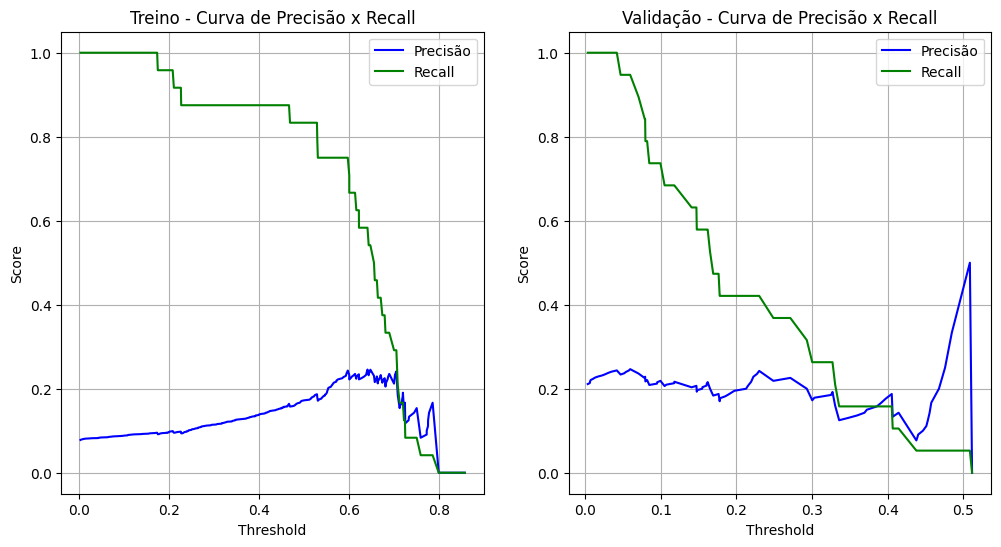

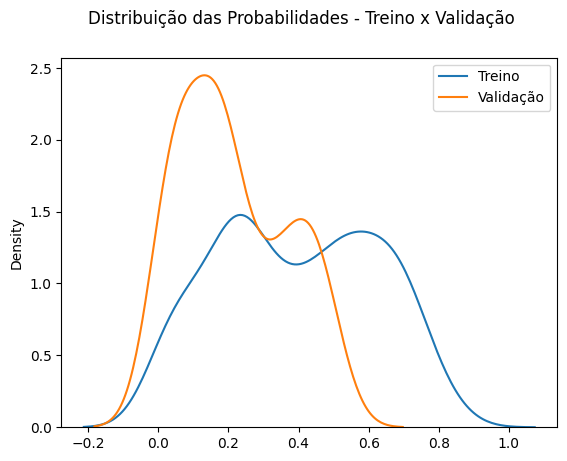

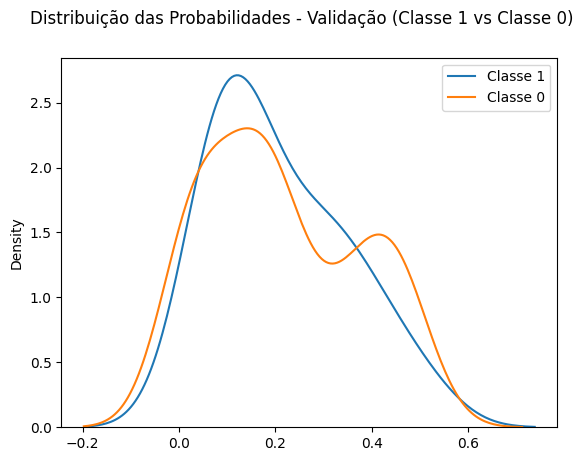

In [22]:
recall_minimo = None
precisao_minima = 0.5
resultado = tr.avaliar_e_logar_modelo(modelo_rl, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss,dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# Redução de features

In [20]:
# Importâncias
importancias = pd.Series(modelo_rl.coef_[0], index=X_train.columns)
df_importancias = pd.DataFrame({
    'Feature': importancias.index,
    'importancia': importancias.values,
    'importancia_abs': importancias.abs().values
})
df_importancias.sort_values(by='importancia_abs', ascending=False, inplace=True)
df_importancias.head(15)


,Feature,importancia,importancia_abs
20,volume_std,-2.165327e-07,2.165327e-07
21,volume_trend,-2.120988e-07,2.120988e-07
65,obv_trend,-7.163024e-08,7.163024e-08
63,obv_std,-3.005102e-08,3.005102e-08
73,retorno_ponderado_vol_mean,-1.165060e-08,1.165060e-08
19,volume_soma,1.010478e-08,1.010478e-08
62,obv_mean,-2.192401e-09,2.192401e-09
18,volume_mean,5.813741e-10,5.813741e-10
64,obv_ultimo,-2.815818e-10,2.815818e-10
4,close_trend,0.000000e+00,0.000000e+00


In [115]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k)['Feature'].tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            #modelo = RandomForestClassifier(n_estimators=100, random_state=42)            
            modelo = LogisticRegression(solver='liblinear', penalty='l2', random_state=42, class_weight='balanced', C=0.001)
            modelo.fit(X_train[colunas_selecionadas], y_train )            

            y_pred = modelo.predict(X_val_teste)

            if (y_pred == 1).sum() > 0:
                # Se não houver predições positivas, não calcular precisão e recall
                
                prec = precision_score(y_val_teste, y_pred, zero_division=0)
                rec = recall_score(y_val_teste, y_pred, zero_division=0)

                precisões.append(prec)
                recalls.append(rec)

        if precisões:  # Verifica se a lista não está vazia
            resultados_precisao[k] = np.mean(precisões)
            resultados_recall[k] = np.mean(recalls)
        else:
            print(f"Nenhuma predição positiva para k={k}. Não foi possível calcular precisão e recall.")

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
#k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
#k_values = [18, 20, 22, 25]
k_values = [5, 10, 50, 70]
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, df_importancias)

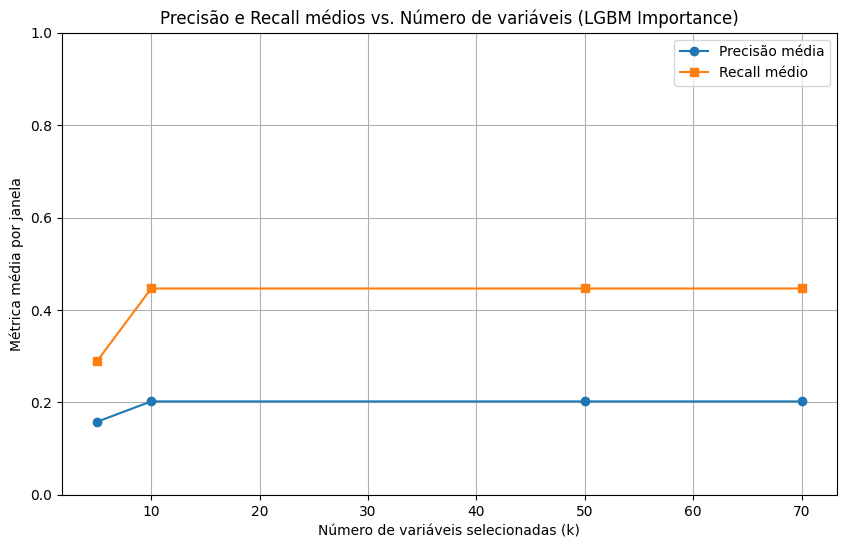

In [116]:
plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (LGBM Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

# Features reduzidas

In [90]:
n_features = 10
lista_colunas_selecionadas = df_importancias.head(n_features)['Feature'].tolist()
lista_colunas_selecionadas

['retorno_ponderado_vol_mean',
 'volume_trend',
 'volume_mean',
 'obv_std',
 'volume_std',
 'obv_ultimo',
 'obv_mean',
 'obv_trend',
 'adc_adx_ultimo_BBAS3',
 'adc_adx_ultimo_SANB11']

In [91]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

AUC no treino: 0.808
AUC na validação: 0.245
Diferença AUC (Treino - Validação): 0.562
PROVÁVEL OVERFITTING
PR AUC no treino: 0.678
PR AUC na validação: 0.236
Diferença PR AUC (Treino - Validação): 0.443
F1 Score no treino: 0.642
F1 Score na validação: 0.079


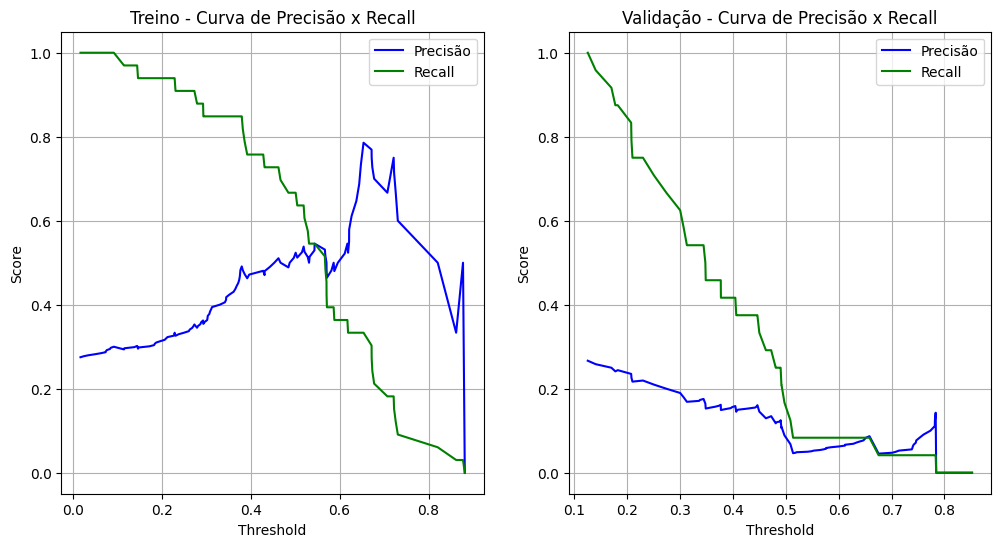

(np.float64(0.8076231483516545),
 np.float64(0.24543080254088323),
 np.float64(0.5621923458107713),
 np.float64(0.6781640606488013),
 np.float64(0.23560944336825881),
 np.float64(0.6421388012331591),
 np.float64(0.07875266497111882))

In [92]:
modelo_rl_reduzido = LogisticRegression(solver='liblinear', random_state=42, class_weight={0:1, 1:2}, C=0.01)
modelo_rl_reduzido.fit(X_train_reduzido, y_train)
tr.comparar_auc_conjuntos(modelo_rl_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: 46a38af0e1b14b17b305c3688e75a7ca para ITUB4.SA_20dias_x_0.03val_5dias_alvo
AUC no treino: 0.568
AUC na validação: 0.586

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.614
  Precisão média (em 13 janelas com previsão positiva): 1.000
  Recall médio: 0.003

Calibrando thresholds para precisão mínima de 0.65...

Threshold Ideal Selecionado: 0.50
  Precisão Média Esperada: 100.00%
  Recall Médio Esperado: 0.25%
  Janelas Usadas para Precisão: 13.0

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 55 janelas com previsão positiva): 0.533
Recall médio: 0.069
Sinais de compra presentes na vallidação: 25.0
Sinais de compra previstos na validação: 8
Modelo ITUB4.SA_20dias_x_0.0

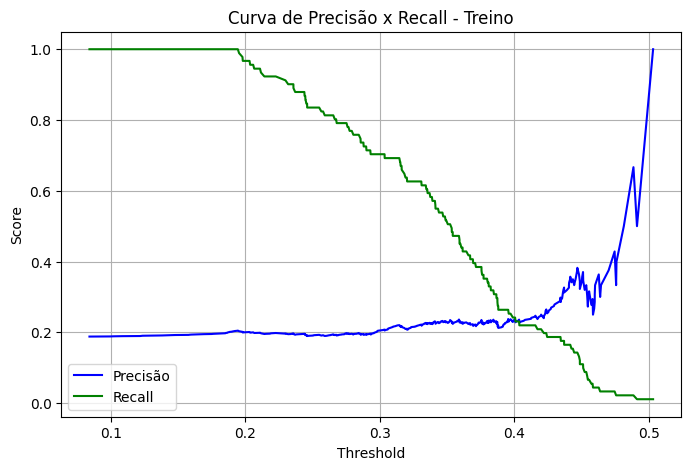

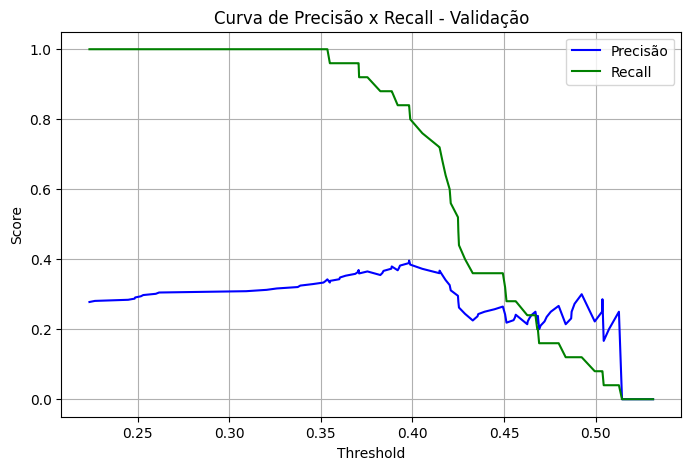

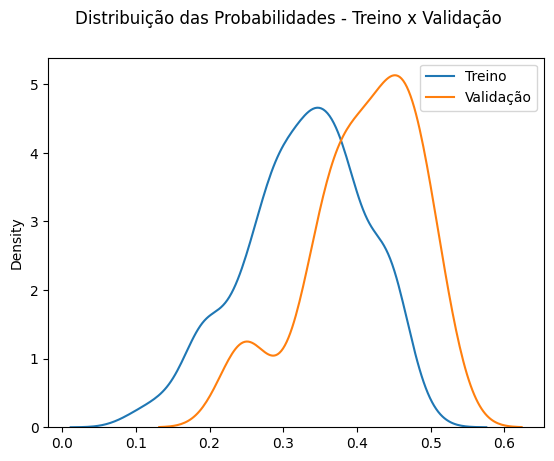

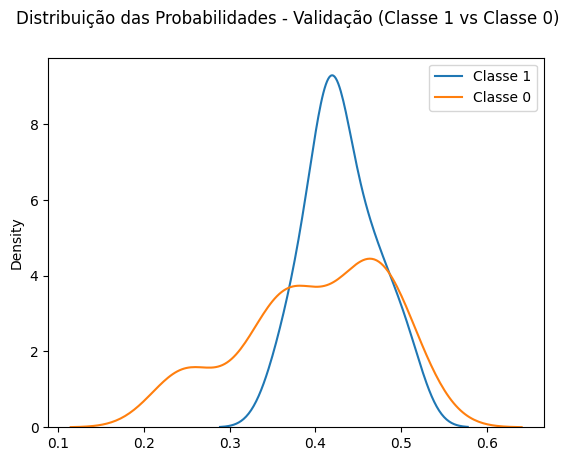

In [25]:
recall_minimo = None
precisao_minima = 0.65
resultado = tr.avaliar_e_logar_modelo(modelo_rl_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# LGBM GOOGLE

## Versão com early stopping

In [39]:
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import TimeSeriesSplit # Para o CV interno da calibração, se optar por essa via
from sklearn.metrics import roc_auc_score
import lightgbm as lgbm # Para o callback de early stopping
from sklearn.frozen import FrozenEstimator

def criar_e_treinar_modelo_final_com_es_e_calib(
        X_super_treino_completo: pd.DataFrame, # Seus 510 dias
        y_super_treino_completo: pd.Series,
        fracao_eval_es: float = 0.2, # % do X_super_treino a ser usado para eval_set do Early Stopping
        lgbm_params: dict = None,
        early_stopping_rounds_lgbm: int = 50,
        eval_metric_lgbm: str = 'auc',
        calibrar_modelo: bool = True,
        metodo_calibracao: str = 'isotonic',
        # Opção A para calibração: usar o mesmo eval_set_es para cv='prefit'
        # Opção B para calibração: usar TimeSeriesSplit no X_treino_base_lgbm para cv do CalibratedCV
        estrategia_calibracao_cv = 'prefit' # ou um objeto TimeSeriesSplit(n_splits=3)
        , class_weight: str = 'balanced' 
    ):
    """
    Treina o modelo final (LGBM) usando uma parte do X_super_treino_completo para treino
    e outra parte para early stopping. Opcionalmente calibra o modelo.

    Retorna o modelo final treinado (e possivelmente calibrado).
    """
    if not (0 < fracao_eval_es < 1):
        raise ValueError("fracao_eval_es deve estar entre 0 e 1 (exclusivo).")

    n_total_super_treino = len(X_super_treino_completo)
    n_eval_es = int(n_total_super_treino * fracao_eval_es)
    n_treino_base_lgbm = n_total_super_treino - n_eval_es

    if n_treino_base_lgbm < 50 or n_eval_es < 20: # Mínimos arbitrários, ajuste conforme necessário
        raise ValueError(f"Dados insuficientes no X_super_treino para o split de early stopping. "
                         f"Treino Base: {n_treino_base_lgbm}, Eval ES: {n_eval_es}")

    X_treino_base_lgbm = X_super_treino_completo.iloc[:n_treino_base_lgbm]
    y_treino_base_lgbm = y_super_treino_completo.iloc[:n_treino_base_lgbm]
    X_eval_set_es = X_super_treino_completo.iloc[n_treino_base_lgbm:]
    y_eval_set_es = y_super_treino_completo.iloc[n_treino_base_lgbm:]

    print(f"Dividindo Super Treino ({n_total_super_treino} amostras):")
    print(f"  - Treino Base LGBM: {len(X_treino_base_lgbm)} amostras")
    print(f"  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): {len(X_eval_set_es)} amostras")

    # --- 1. Treinar LGBM com Early Stopping ---
    if lgbm_params is None:
        lgbm_params = {
            'n_estimators': 1000, 'learning_rate': 0.01, 'num_leaves': 15,
            'max_depth': 4, 'min_child_samples': 20, 'subsample': 0.8,
            'colsample_bytree': 0.8, 'random_state': 42, 'n_jobs': -1,
            'class_weight': class_weight,
            'importance_type': 'gain', 

        }

    modelo_lgbm = LGBMClassifier(**lgbm_params)
    print(f"\nIniciando treinamento LGBM com early stopping (monitorando '{eval_metric_lgbm}')...")

    # Certificar que X_treino_base_lgbm.values e X_eval_set_es.values são usados se as funções esperam arrays
    # Se X são DataFrames, LGBM geralmente lida bem, mas para consistência com sklearn:
    X_treino_lgbm_arr = X_treino_base_lgbm.values if isinstance(X_treino_base_lgbm, pd.DataFrame) else X_treino_base_lgbm
    y_treino_lgbm_arr = y_treino_base_lgbm.values if isinstance(y_treino_base_lgbm, pd.Series) else y_treino_base_lgbm
    X_eval_es_arr = X_eval_set_es.values if isinstance(X_eval_set_es, pd.DataFrame) else X_eval_set_es
    y_eval_es_arr = y_eval_set_es.values if isinstance(y_eval_set_es, pd.Series) else y_eval_set_es

    modelo_lgbm.fit(
        X_treino_lgbm_arr, y_treino_lgbm_arr,
        eval_set=[(X_eval_es_arr, y_eval_es_arr)],
        eval_metric=eval_metric_lgbm,
        callbacks=[lgbm.early_stopping(stopping_rounds=early_stopping_rounds_lgbm, verbose=10)]
    )
    print(f"Treinamento LGBM concluído. Melhor iteração: {modelo_lgbm.best_iteration_}")
    # Após o ES, o modelo_lgbm já está treinado com o número ótimo de árvores.

    if not calibrar_modelo:
        return modelo_lgbm # Retorna o LGBM treinado sem calibração

    # --- 2. Calibrar o Modelo Treinado ---
    print(f"\nCalibrando o LGBM treinado (método: {metodo_calibracao})...")
    
    

    if estrategia_calibracao_cv == "prefit":
        # Usa o X_eval_set_es para treinar o calibrador.
        # Este conjunto já foi "visto" para determinar n_estimators, então não é 100% puro
        # para calibração, mas é uma prática comum.
        print(f"  Usando conjunto de early stopping ({len(X_eval_set_es)} amostras) para treinar o calibrador (cv='prefit').")

        modelo_frozen = FrozenEstimator(modelo_lgbm) # Congela o modelo LGBM treinado com ES
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_frozen, # O modelo LGBM JÁ TREINADO com ES e congelado
            method=metodo_calibracao            
            )
        modelo_final_calibrado.fit(X_eval_es_arr, y_eval_es_arr)
    elif isinstance(estrategia_calibracao_cv, TimeSeriesSplit):
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_lgbm, # O modelo LGBM JÁ TREINADO com ES
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv # Pode ser "prefit" ou um objeto TimeSeriesSplit
            )
        # Treina o CalibratedClassifierCV no X_treino_base_lgbm.
        # O CalibratedCV irá internamente usar o LGBM (já com n_estimators ótimo)
        # e fazer cross-validation no X_treino_base_lgbm para ajustar o calibrador.
        # O estimador base (LGBM) NÃO é retreinado do zero pelo CalibratedCV se já tiver fit e cv='prefit'
        # MAS, se cv é um objeto splitter, ele *pode* retreinar o base_estimator em cada fold.
        # Para evitar retreinar o LGBM que já teve ES, a abordagem com 'prefit' é mais direta.
        # Se você quiser usar um splitter para o CV da calibração, é mais seguro
        # passar um LGBM *não treinado* para CalibratedCV, e o CalibratedCV fará o fit
        # do LGBM e do calibrador em seus folds internos. Mas aí você perde o ES global.
        
        # A maneira mais limpa se não usar 'prefit' para o CalibratedCV é
        # fazer com que ele treine um LGBM novo (sem ES global) em seus folds.
        # Ou, você pode fazer o ES em cada fold do CalibratedCV (mais complexo).

        # Simplificação: Se não for 'prefit', vamos assumir que você quer que o CalibratedCV
        # treine o LGBM base (com os params definidos) e o calibrador nos folds do X_treino_base_lgbm.
        # Isso ignora o `modelo_lgbm` treinado com ES anteriormente, a menos que
        # o `base_estimator` do CalibratedCV seja clonado e o `n_estimators` ótimo seja setado.
        # Vamos manter a lógica de 'prefit' como principal ou usar CV no conjunto de treino base.
        print(f"  Usando TimeSeriesSplit no Treino Base LGBM ({len(X_treino_base_lgbm)} amostras) para treinar o calibrador.")
        
        # Reinstanciar o LGBM com os parâmetros e n_estimators ótimos
        # para ser usado pelo CalibratedClassifierCV com seu próprio CV.
        # Isso garante que o n_estimators do ES seja usado em cada fold do CalibratedCV.
        params_lgbm_com_best_iter = modelo_lgbm.get_params()
        if hasattr(modelo_lgbm, 'best_iteration_') and modelo_lgbm.best_iteration_ is not None:
             params_lgbm_com_best_iter['n_estimators'] = modelo_lgbm.best_iteration_
        
        lgbm_para_calib_cv = LGBMClassifier(**params_lgbm_com_best_iter)

        modelo_final_calibrado_cv = CalibratedClassifierCV(
            lgbm_para_calib_cv,
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv
        )
        modelo_final_calibrado_cv.fit(X_treino_lgbm_arr, y_treino_lgbm_arr) # Treina no treino base
        print("Calibração com CV interno concluída.")
        return modelo_final_calibrado_cv # Retorna o modelo calibrado com CV
    else:
        raise ValueError(f"estrategia_calibracao_cv desconhecida: {estrategia_calibracao_cv}. Use 'prefit' ou um objeto TimeSeriesSplit.")

    print("Calibração concluída.")
    return modelo_final_calibrado, modelo_lgbm

Dividindo Super Treino (470 amostras):
  - Treino Base LGBM: 353 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 117 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[90]	valid_0's auc: 0.538038	valid_0's binary_logloss: 0.608881
Treinamento LGBM concluído. Melhor iteração: 90

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (117 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.836
AUC na validação: 0.299
Diferença AUC (Treino - Validação): 0.537
PROVÁVEL OVERFITTING
PR AUC no treino: 0.530
PR AUC na validação: 0.193
Diferença PR AUC (Treino - Validação): 0.337
F1 Score no treino: 0.413
F1 Score na validação: 0.000


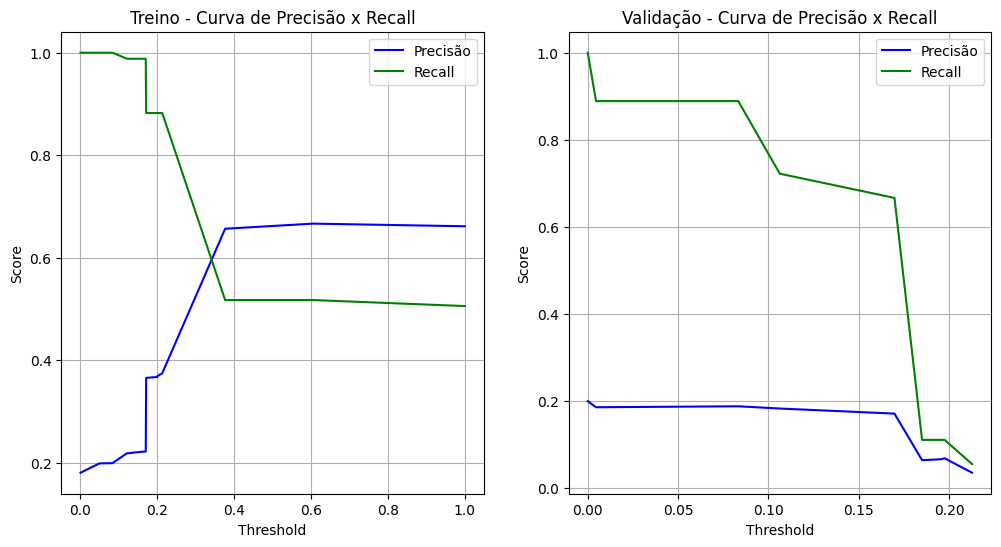

(np.float64(0.8360404279453387),
 np.float64(0.2994226249952539),
 np.float64(0.5366178029500848),
 np.float64(0.5299154668604668),
 np.float64(0.19288063655132798),
 np.float64(0.41306212038791273),
 np.float64(0.0))

In [57]:
# --- Seu fluxo principal (para cada papel) ---
# Supondo que X_super_train_papel, y_super_train_papel (510 dias)
# e X_validacao_final_papel, y_validacao_final_papel (90 dias) estão definidos.
lgbm_params = {
    'n_estimators': 1000,
    'learning_rate': 0.01,          # Pode ser um pouco mais alto, pois o modelo é muito restrito

    # --- Regularização da Árvore (Agressiva) ---
    'num_leaves': 8,                # BEM REDUZIDO: Árvores muito simples.
    'max_depth': 4,                 # BEM REDUZIDO: Árvores muito rasas.
    'min_child_samples': 50,        # BEM AUMENTADO: Exige muitos dados por folha.
    'min_gain_to_split': 0.1,       # AUMENTADO: A penalidade para split é maior.

    # --- Regularização por Amostragem e Penalidade (Agressiva) ---
    'subsample': 0.7,
    'colsample_bytree': 0.7,
    'reg_alpha': 1.0,               # AUMENTADO: Penalidade L1 mais forte.
    'reg_lambda': 1.0,              # AUMENTADO: Penalidade L2 mais forte.
    
    # --- Outros Parâmetros ---
    'random_state': 42,
    'n_jobs': -1,
    'class_weight': class_weight,
    'importance_type': 'gain',
    'verbosity': -1
}


# 1. Treinar o modelo
#    Você escolhe a estratégia de calibração:
#    Opção A: Calibrar com 'prefit' usando o mesmo eval_set do ES (mais simples, pequeno reuso)
modelo_treinado, modelo_original = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train, y_train,
    fracao_eval_es=0.25, # Ex: 20% do super treino para ES e calibração prefit
    lgbm_params=lgbm_params,
    eval_metric_lgbm='auc',
    estrategia_calibracao_cv='prefit',
    class_weight='balanced'#{0:1, 1:4} # Ajuste conforme necessário
)
#modelo_treinado.fit(X_train.values, y_train.values)  # Fit final após calibração

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_treinado, X_train, y_train, X_validacao, y_validacao)

## Tentativa de simplicação de features

In [61]:
X_train.shape

(470, 126)

In [60]:
modelo_rl_simplificacao = LogisticRegression(solver='liblinear', penalty='l1', class_weight='balanced', C=0.1)
modelo_rl_simplificacao.fit(X_train, y_train)
series_coef = pd.Series(modelo_rl_simplificacao.coef_[0], index=X_train.columns)
series_coef = series_coef[series_coef.abs() > 0] # Remove coeficientes zero
lista_colunas_selecionadas_rl = series_coef.index.tolist()
print(f"Colunas selecionadas pela Regressão Logística: {lista_colunas_selecionadas_rl}")
print(f"Número de colunas selecionadas: {len(lista_colunas_selecionadas_rl)}")


Colunas selecionadas pela Regressão Logística: ['close_min', 'volume_mean', 'volume_std', 'volume_trend', 'rsi_std', 'rsi_ultimo', 'close_amplitude_norm_atr_principal', 'obv_mean', 'obv_std', 'obv_ultimo', 'obv_trend', 'retorno_ponderado_vol_mean', 'adx_ultimo', 'bbands_largura_pct_ultimo', 'adc_adx_ultimo_BBAS3', 'adc_bbands_largura_pct_ultimo_BBAS3', 'adc_adx_ultimo_BBDC4', 'adc_adx_trend_BBDC4', 'adc_bbands_largura_pct_ultimo_BBDC4', 'adc_adx_ultimo_SANB11', 'adc_bbands_largura_pct_ultimo_SANB11', 'adc_close_mean_geral_ultimo']
Número de colunas selecionadas: 22


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\svm\_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [62]:
x_train_simplificado = X_train[lista_colunas_selecionadas_rl].copy()
x_validacao_simplificado = X_validacao[lista_colunas_selecionadas_rl].copy()

Dividindo Super Treino (470 amostras):
  - Treino Base LGBM: 353 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 117 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[3]	valid_0's auc: 0.583014	valid_0's binary_logloss: 0.686237
Treinamento LGBM concluído. Melhor iteração: 3

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (117 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.750
AUC na validação: 0.322
Diferença AUC (Treino - Validação): 0.428
PROVÁVEL OVERFITTING
PR AUC no treino: 0.406
PR AUC na validação: 0.224
Diferença PR AUC (Treino - Validação): 0.181
F1 Score no treino: 0.154
F1 Score na validação: 0.000


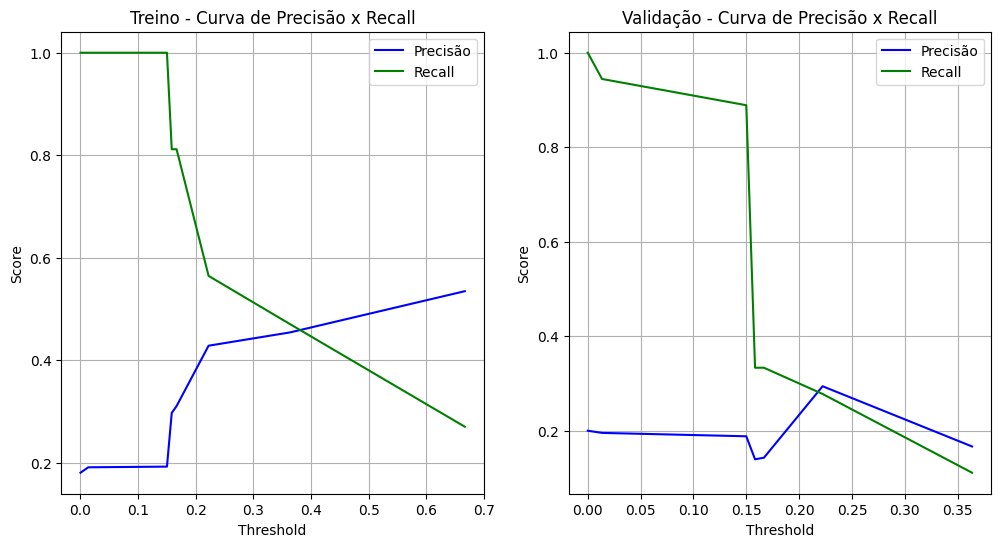

(np.float64(0.7497669719024249),
 np.float64(0.32173396823097083),
 np.float64(0.4280330036714541),
 np.float64(0.40553015279651666),
 np.float64(0.22439153455745706),
 np.float64(0.15410035818407736),
 np.float64(0.0))

In [63]:
# --- Seu fluxo principal (para cada papel) ---
# Supondo que X_super_train_papel, y_super_train_papel (510 dias)
# e X_validacao_final_papel, y_validacao_final_papel (90 dias) estão definidos.
lgbm_params = {
    'n_estimators': 1000,
    'learning_rate': 0.01,          # Pode ser um pouco mais alto, pois o modelo é muito restrito

    # --- Regularização da Árvore (Agressiva) ---
    'num_leaves': 8,                # BEM REDUZIDO: Árvores muito simples.
    'max_depth': 4,                 # BEM REDUZIDO: Árvores muito rasas.
    'min_child_samples': 50,        # BEM AUMENTADO: Exige muitos dados por folha.
    'min_gain_to_split': 0.1,       # AUMENTADO: A penalidade para split é maior.

    # --- Regularização por Amostragem e Penalidade (Agressiva) ---
    'subsample': 0.7,
    'colsample_bytree': 0.7,
    'reg_alpha': 1.0,               # AUMENTADO: Penalidade L1 mais forte.
    'reg_lambda': 1.0,              # AUMENTADO: Penalidade L2 mais forte.
    
    # --- Outros Parâmetros ---
    'random_state': 42,
    'n_jobs': -1,
    'class_weight': class_weight,
    'importance_type': 'gain',
    'verbosity': -1
}


# 1. Treinar o modelo
#    Você escolhe a estratégia de calibração:
#    Opção A: Calibrar com 'prefit' usando o mesmo eval_set do ES (mais simples, pequeno reuso)
modelo_treinado, modelo_original = criar_e_treinar_modelo_final_com_es_e_calib(
    x_train_simplificado, y_train,
    fracao_eval_es=0.25, # Ex: 20% do super treino para ES e calibração prefit
    lgbm_params=lgbm_params,
    eval_metric_lgbm='auc',
    estrategia_calibracao_cv='prefit',
    class_weight='balanced'#{0:1, 1:4} # Ajuste conforme necessário
)
#modelo_treinado.fit(X_train.values, y_train.values)  # Fit final após calibração

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_treinado, x_train_simplificado, y_train, x_validacao_simplificado, y_validacao)

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: d46ae7a576fd44c08604c2923ded1c32 para ITUB4.SA_15dias_x_0.03val_5dias_alvo
AUC no treino: 0.822
AUC na validação: 0.275

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.802
  Precisão média (em 130 janelas com previsão positiva): 0.929
  Recall médio: 0.118

Calibrando thresholds para precisão mínima de 0.65...

Threshold Ideal Selecionado: 0.50
  Precisão Média Esperada: 92.86%
  Recall Médio Esperado: 11.79%
  Janelas Usadas para Precisão: 130.0

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 0 janelas com previsão positiva): 0.000
Recall médio: 0.000
Sinais de compra presentes na vallidação: 24.0
Sinais de compra previstos na validação: 0


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Modelo ITUB4.SA_15dias_x_0.03val_5dias_alvo salvo na run d46ae7a576fd44c08604c2923ded1c32


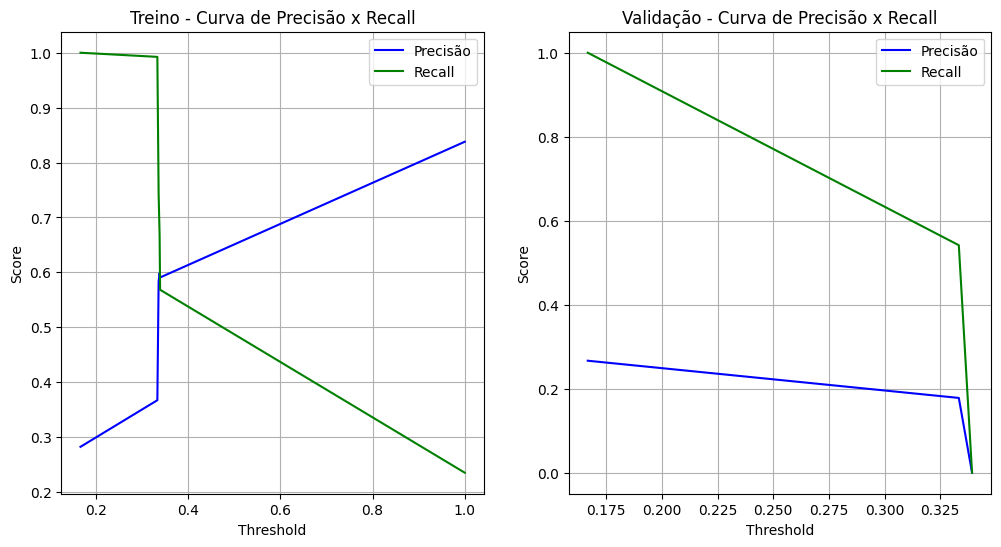

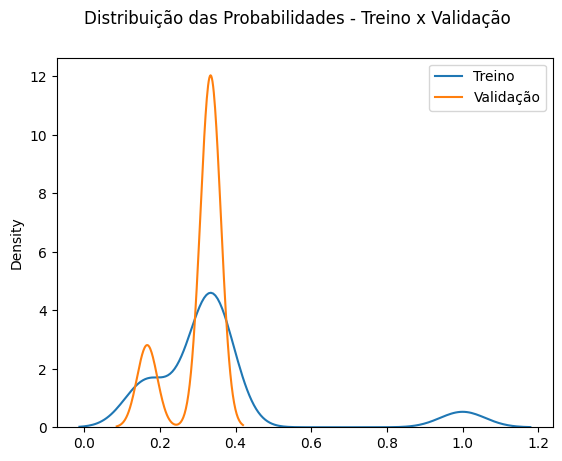

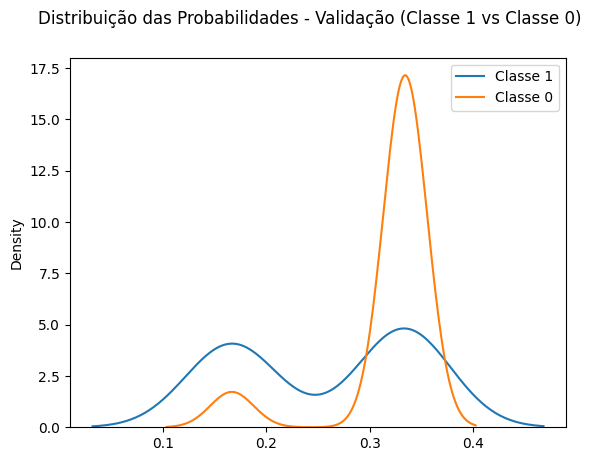

In [82]:
recall_minimo = None
precisao_minima = 0.65
resultado = tr.avaliar_e_logar_modelo(modelo_treinado, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# Redução de features

In [29]:
# Importâncias
importancias = pd.Series(modelo_original.feature_importances_, index=X_train.columns)
importancias = importancias.sort_values(ascending=False)
importancias.head(15)


close_dist_min                     1.115400e+02
tr_std                             7.661790e+01
adc_close_trend_BBAS3              6.315810e+01
adc_atr_pct_ultimo_SANB11          5.404031e+01
macd_mean                          1.332250e+01
adc_correl_com_principal_SANB11    1.191880e+01
adc_close_mean_geral_ultimo        9.377740e+00
macd_std_norm_atr_principal        6.785530e+00
volume_ult_vs_mean                 1.380550e-01
close_trend                        1.330110e-01
close_max                          3.552710e-15
retorno_desde_mudanca_close        0.000000e+00
retorno_medio_neg                  0.000000e+00
volume_std                         0.000000e+00
volume_trend                       0.000000e+00
dtype: float64

In [30]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            #modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            
            modelo, _ = criar_e_treinar_modelo_final_com_es_e_calib(
                X_train[colunas_selecionadas], y_train,
                fracao_eval_es=0.25, # Ex: 20% do super treino para ES e calibração prefit
                estrategia_calibracao_cv='prefit'
            )            

            y_pred = modelo.predict(X_val_teste)

            if (y_pred == 1).sum() > 0:
                # Se não houver predições positivas, não calcular precisão e recall
                
                prec = precision_score(y_val_teste, y_pred, zero_division=0)
                rec = recall_score(y_val_teste, y_pred, zero_division=0)

                precisões.append(prec)
                recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
#k_values = [18, 20, 22, 25]
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, importancias)

Dividindo Super Treino (484 amostras):
  - Treino Base LGBM: 363 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 121 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
[LightGBM] [Info] Number of positive: 77, number of negative: 286
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000091 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 588
[LightGBM] [Info] Number of data points in the train set: 363, number of used features: 5
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[Lig

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

... (470 outputs left out)

[LightGBM] [Info] Number of positive: 77, number of negative: 286
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000369 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 5786
[LightGBM] [Info] Number of data points in the train set: 363, number of used features: 50
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[Lig

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

Early stopping, best iteration is:
[26]	valid_0's auc: 0.699599	valid_0's binary_logloss: 0.642438
Treinamento LGBM concluído. Melhor iteração: 26

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (121 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.
Dividindo Super Treino (484 amostras):
  - Treino Base LGBM: 363 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 121 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
[LightGBM] [Info] Number of positive: 77, number of negative: 286
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000419 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 5786
[LightGBM] [Info] Number of data points in the train set: 363, number of used features: 50
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start traini

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

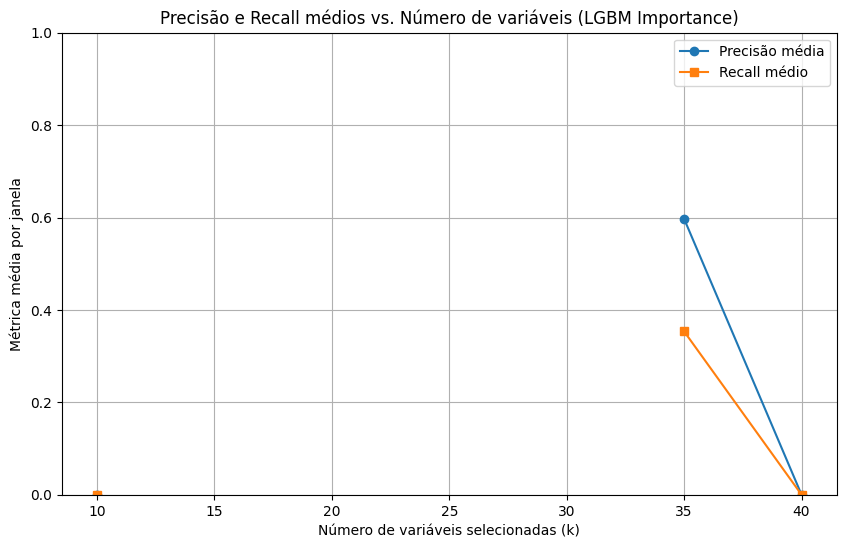

In [31]:
plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (LGBM Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

# Features reduzidas

In [32]:
n_features = 15
lista_colunas_selecionadas = importancias.head(n_features).index.tolist()
lista_colunas_selecionadas

['close_dist_min',
 'tr_std',
 'adc_close_trend_BBAS3',
 'adc_atr_pct_ultimo_SANB11',
 'macd_mean',
 'adc_correl_com_principal_SANB11',
 'adc_close_mean_geral_ultimo',
 'macd_std_norm_atr_principal',
 'volume_ult_vs_mean',
 'close_trend',
 'close_max',
 'retorno_desde_mudanca_close',
 'retorno_medio_neg',
 'volume_std',
 'volume_trend']

In [33]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [34]:
modelo_reduzido, _ = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train_reduzido, y_train,
    fracao_eval_es=0.25, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit',
    metodo_calibracao='isotonic'    
)

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

Dividindo Super Treino (484 amostras):
  - Treino Base LGBM: 363 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 121 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
[LightGBM] [Info] Number of positive: 77, number of negative: 286
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000274 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1677
[LightGBM] [Info] Number of data points in the train set: 363, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [W

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.858
AUC na validação: 0.567
Diferença AUC (Treino - Validação): 0.290
PROVÁVEL OVERFITTING
PR AUC no treino: 0.582
PR AUC na validação: 0.418
Diferença PR AUC (Treino - Validação): 0.164
F1 Score no treino: 0.137
F1 Score na validação: 0.000


(np.float64(0.8578195937158385),
 np.float64(0.5674171292152863),
 np.float64(0.2904024645005522),
 np.float64(0.5824022700790085),
 np.float64(0.41794230766585544),
 np.float64(0.137063377515191),
 np.float64(0.0))

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: b5e3b33918944b79a4649fd85b1e5588 para ITUB4.SA_20dias_x_0.03val_5dias_alvo
AUC no treino: 0.879
AUC na validação: 0.534

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.858
  Precisão média (em 100 janelas com previsão positiva): 0.995
  Recall médio: 0.090

Calibrando thresholds para precisão mínima de 0.70...

Threshold Ideal Selecionado: 0.50
  Precisão Média Esperada: 99.50%
  Recall Médio Esperado: 8.96%
  Janelas Usadas para Precisão: 100.0

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 3 janelas com previsão positiva): 0.000
Recall médio: 0.000
Sinais de compra presentes na vallidação: 25.0
Sinais de compra previstos na validação: 1
Modelo ITUB4.SA_20dias_x_0.0

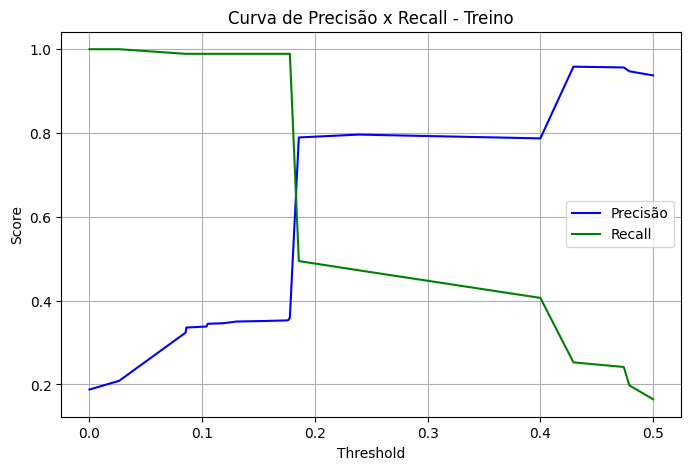

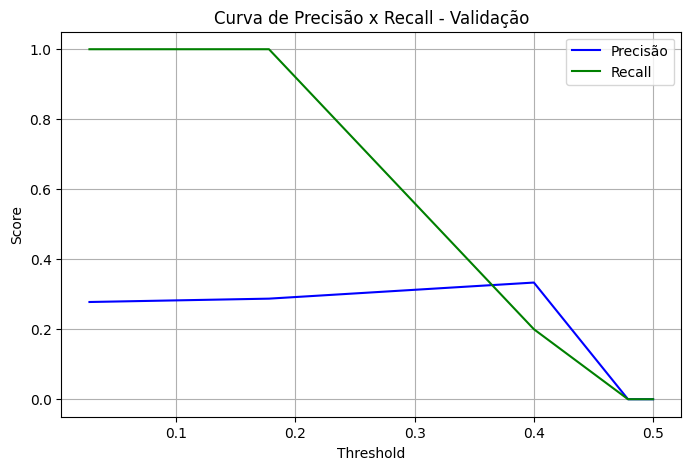

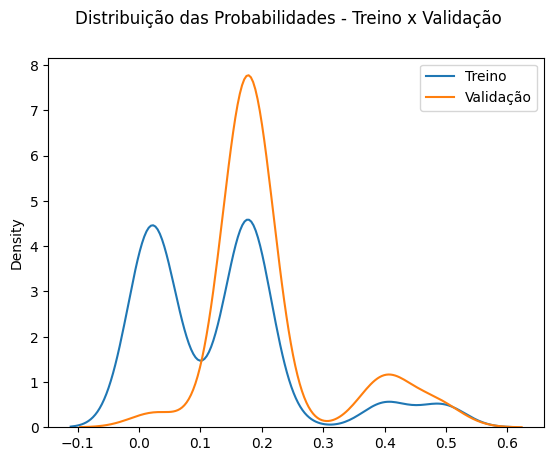

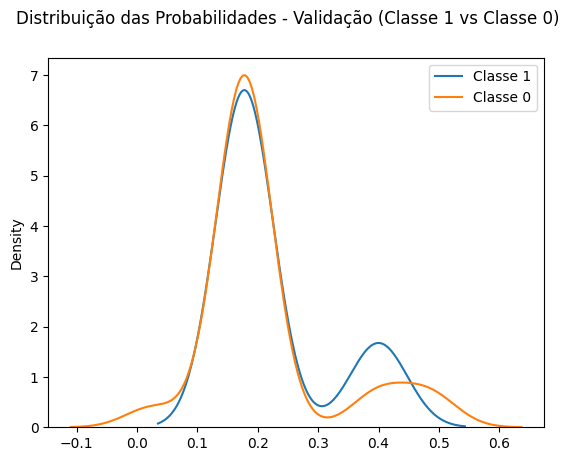

In [35]:
precisao_minima = 0.7
recall_minimo = None
resultado = tr.avaliar_e_logar_modelo(modelo_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss ,dias_futuro_valorizacao=DIAS_FUTURO, dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

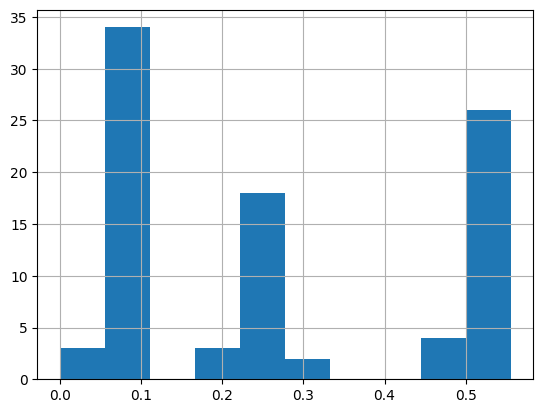

In [ ]:
pd.Series(probas).hist()

In [ ]:
pd.Series(probas).describe()

count    90.000000
mean      0.282092
std       0.196518
min       0.000000
25%       0.105263
50%       0.241379
75%       0.555556
max       0.555556
dtype: float64